In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

In [2]:
titanic= sns.load_dataset("titanic")

In [3]:
titanic.info()
titanic.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [4]:
features= ["pclass","sex","fare","embarked", "age"]
target= ["survived"]

In [5]:
# using simple imputer 
from sklearn.impute import SimpleImputer
imp_median= SimpleImputer(strategy="median") # median for numerical data
titanic[["age"]]= imp_median.fit_transform(titanic[["age"]]) # since imputer expects a 2D vale so used "[[]]"

imp_freq= SimpleImputer(strategy="most_frequent")
titanic[["embarked"]]= imp_freq.fit_transform(titanic[["embarked"]])

In [6]:
# label encoding
from sklearn.preprocessing import LabelEncoder

le= LabelEncoder()
titanic["sex"]= le.fit_transform(titanic["sex"])

titanic["embarked"]= le.fit_transform(titanic["embarked"])

In [7]:
X= titanic[features]
y= titanic[target]

In [8]:
X.head()

,pclass,sex,fare,embarked,age
0,3,1,7.2500,2,22.0
1,1,0,71.2833,0,38.0
2,3,0,7.9250,2,26.0
3,1,0,53.1000,2,35.0
4,3,1,8.0500,2,35.0


In [9]:
X_train, X_test, y_train, y_test= train_test_split(X,y, random_state=42,test_size=0.2)

In [10]:
# buildind decission tree without pruning
from sklearn.tree import DecisionTreeClassifier # by default it uses gini value

model= DecisionTreeClassifier()
model.fit(X_train, y_train)

DecisionTreeClassifier()

In [11]:
from sklearn.metrics import accuracy_score
y_pred= model.predict(X_test)

print("Accuracy", accuracy_score(y_test, y_pred))

Accuracy 0.776536312849162


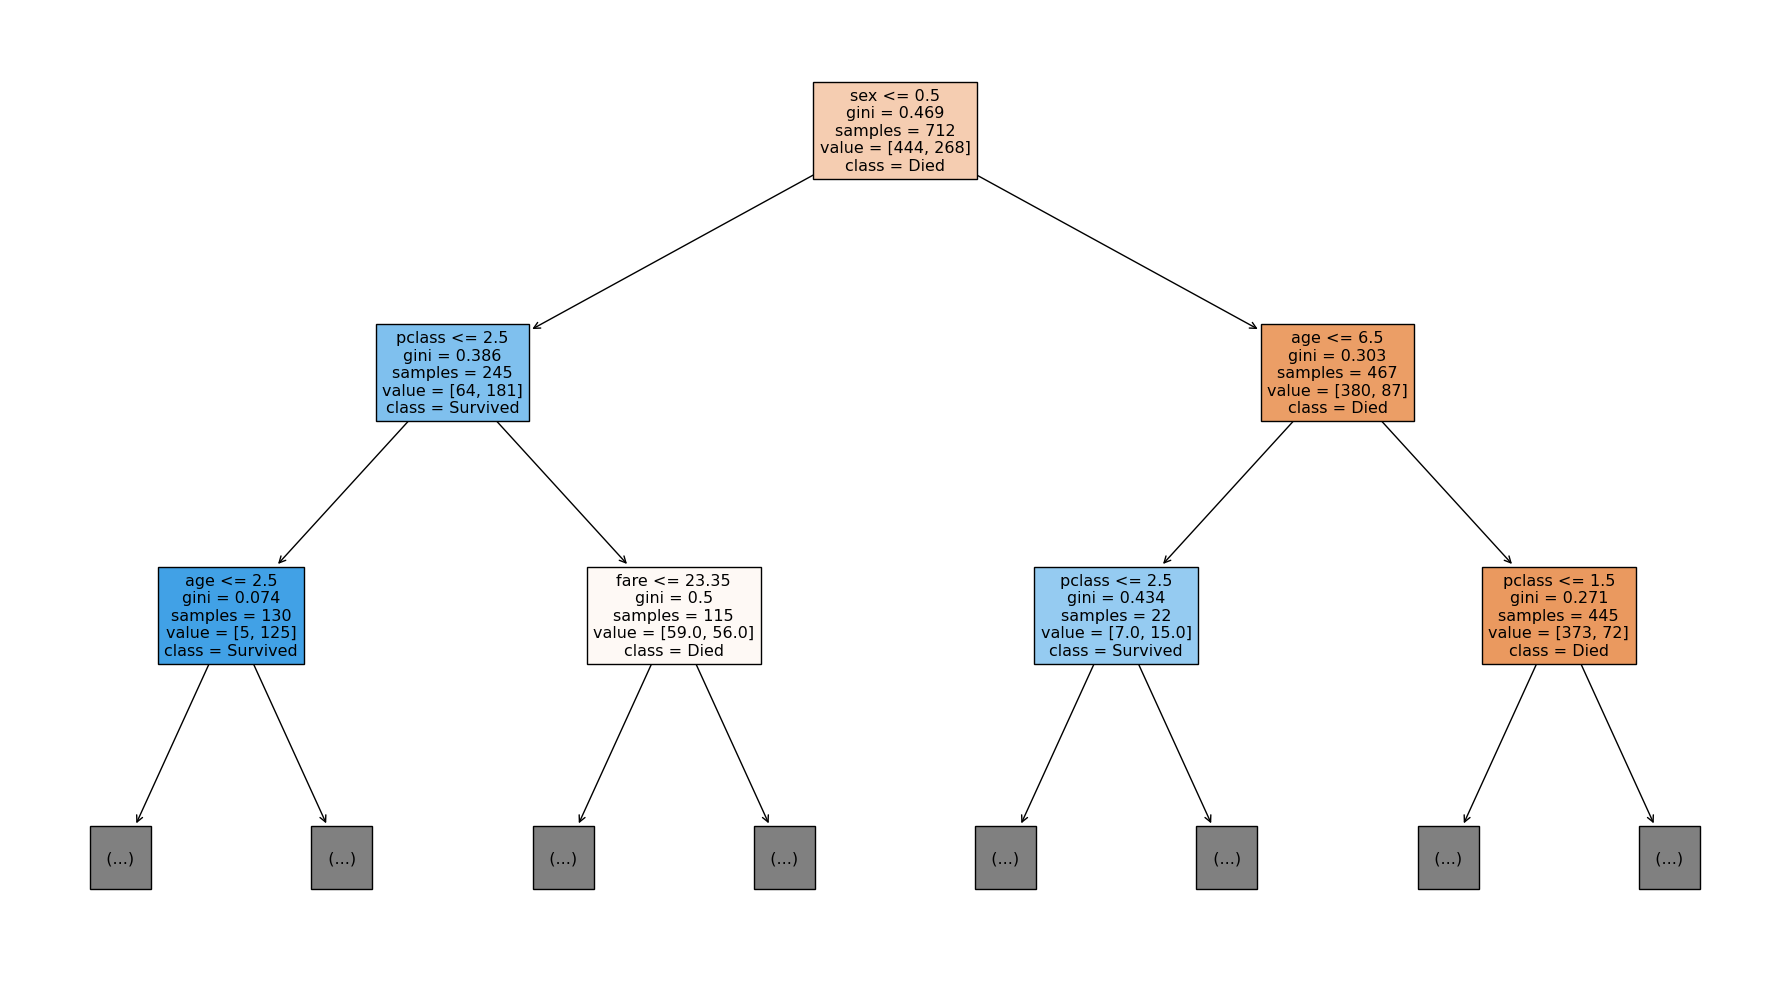

In [12]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18,10))

plot_tree(
    model, # this is the model we have used
    feature_names=X.columns, # The featues we want to make the tree on
    class_names=["Died","Survived"], # what content to show on 0(died) and 1(survived)
    filled=True, # do we want the tree with detailes inside or not
    max_depth=2 # will show only the first 4 layres of the tree, otherwise full tree
)
plt.tight_layout()
plt.show()

# from first node in decision tree its alwayes true on left and false on right based on the fist feature in this case "sex", also since its encoded 
# so no. more towards 1 is male and if more towards 0 its female.

# Decision tree with pre-pruning

In [14]:
# first seeing what max depth to use
max_depths =[2,3,4,5,6,7,8,9,10]

for depth in max_depths:
    model=DecisionTreeClassifier(max_depth=depth)
    model.fit(X_train,y_train)

    acc= model.score(X_test, y_test) # default score is acuracy
    print(f"for depth= {depth}, accuracy={acc} ")

for depth= 2, accuracy=0.7653631284916201 
for depth= 3, accuracy=0.7988826815642458 
for depth= 4, accuracy=0.7988826815642458 
for depth= 5, accuracy=0.7988826815642458 
for depth= 6, accuracy=0.7988826815642458 
for depth= 7, accuracy=0.7877094972067039 
for depth= 8, accuracy=0.7988826815642458 
for depth= 9, accuracy=0.7877094972067039 
for depth= 10, accuracy=0.7988826815642458 


In [15]:
# know seeing what min no. of samples to have
min_sample_splits =[10,15,20,25,30,35,40]

for split in min_sample_splits:
    model=DecisionTreeClassifier(min_samples_split=split)
    model.fit(X_train,y_train)

    sam= model.score(X_test, y_test) # default score is acuracy
    print(f"for depth= {split}, accuracy={sam} ")

for depth= 10, accuracy=0.8100558659217877 
for depth= 15, accuracy=0.8156424581005587 
for depth= 20, accuracy=0.8212290502793296 
for depth= 25, accuracy=0.8044692737430168 
for depth= 30, accuracy=0.7988826815642458 
for depth= 35, accuracy=0.8100558659217877 
for depth= 40, accuracy=0.8100558659217877 


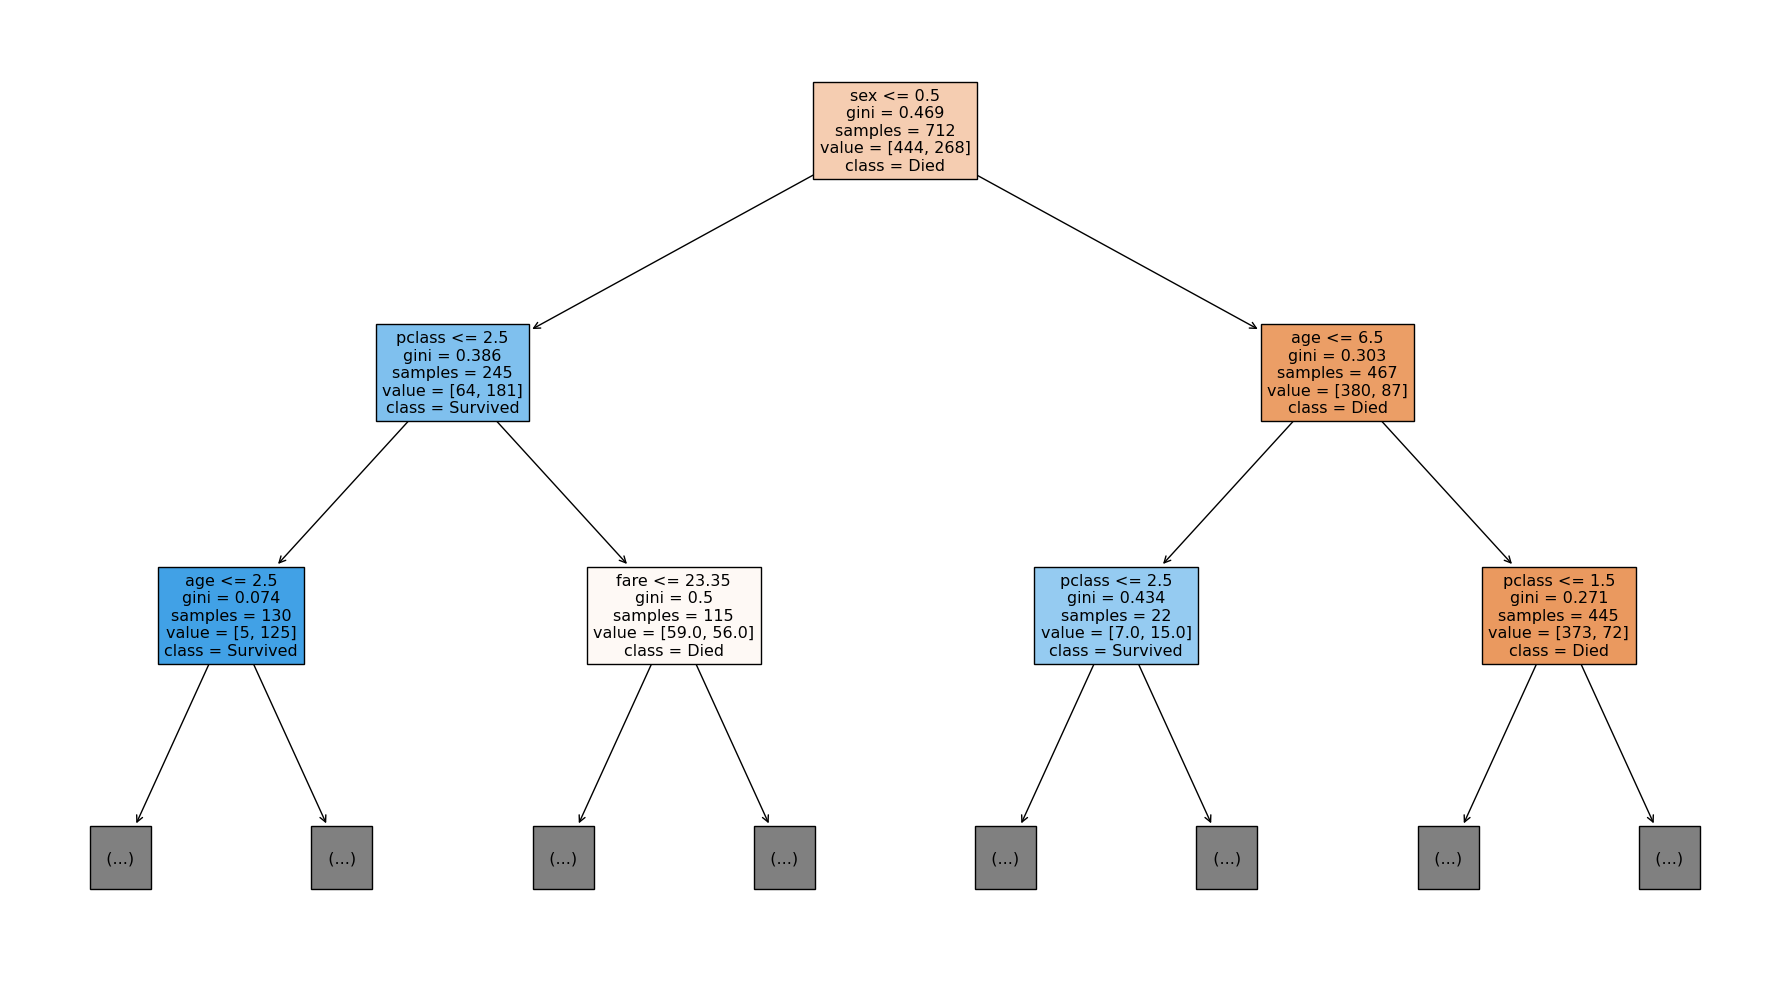

In [16]:
from sklearn.tree import DecisionTreeClassifier # so by pre-pruning the resuls are

model= DecisionTreeClassifier(min_samples_split=20, max_depth=6)
model.fit(X_train, y_train)

plt.figure(figsize=(18,10))

plot_tree(
    model,
    feature_names=X.columns, 
    class_names=["Died","Survived"], 
    filled=True, 
    max_depth=2 
)
plt.tight_layout()
plt.show()

# Decision tree with post-pruning

In [18]:
# fro this we have to frist grow the entire tree
full_tree= DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train,y_train)

DecisionTreeClassifier(random_state=42)

In [19]:
path= full_tree.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas= path.ccp_alphas

print (ccp_alphas) # these are the possible alpha valus ,know we pick the best by trainig will all.

[0.00000000e+00 0.00000000e+00 6.68806849e-05 1.45921494e-04
 1.84428555e-04 2.00642055e-04 2.34082397e-04 2.34082397e-04
 3.51123596e-04 4.68164794e-04 4.68164794e-04 5.61797753e-04
 6.24219725e-04 6.67991230e-04 7.02247191e-04 7.02247191e-04
 8.19288390e-04 8.19288390e-04 8.32292967e-04 8.42696629e-04
 8.42696629e-04 8.42696629e-04 8.94231048e-04 8.99610781e-04
 9.24769963e-04 9.36329588e-04 9.36329588e-04 9.36329588e-04
 9.88347898e-04 1.00253471e-03 1.05337079e-03 1.07400895e-03
 1.08038029e-03 1.11865144e-03 1.12359551e-03 1.12359551e-03
 1.13139825e-03 1.17041199e-03 1.18841832e-03 1.22566125e-03
 1.22893258e-03 1.22893258e-03 1.24361593e-03 1.24843945e-03
 1.27565833e-03 1.30996111e-03 1.33761370e-03 1.37044603e-03
 1.46301498e-03 1.47927070e-03 1.51142557e-03 1.54072312e-03
 1.56675436e-03 1.60434338e-03 1.66892062e-03 1.76144762e-03
 1.86751451e-03 2.10674157e-03 2.34082397e-03 2.41226470e-03
 2.64273538e-03 2.69412911e-03 3.43770913e-03 3.56327570e-03
 5.47433606e-03 9.055400

In [20]:
tree=[]
for alpha in ccp_alphas:
    model=DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    model.fit(X_train,y_train)
    
    tree.append((model, alpha))

In [21]:
best_acc= 0
best_alpha= 0

for model, alpha in tree:
    curr_acc= model.score(X_test, y_test)
    if curr_acc>best_acc:
        best_acc=curr_acc
        best_alpha=alpha

In [22]:
best_alpha

0.0015407231242023183

In [23]:
best_acc

0.8379888268156425

In [24]:
# know we train again on bes alpha
best_model= DecisionTreeClassifier(ccp_alpha=best_alpha)
best_model.fit(X_train,y_train)

DecisionTreeClassifier(ccp_alpha=0.0015407231242023183)

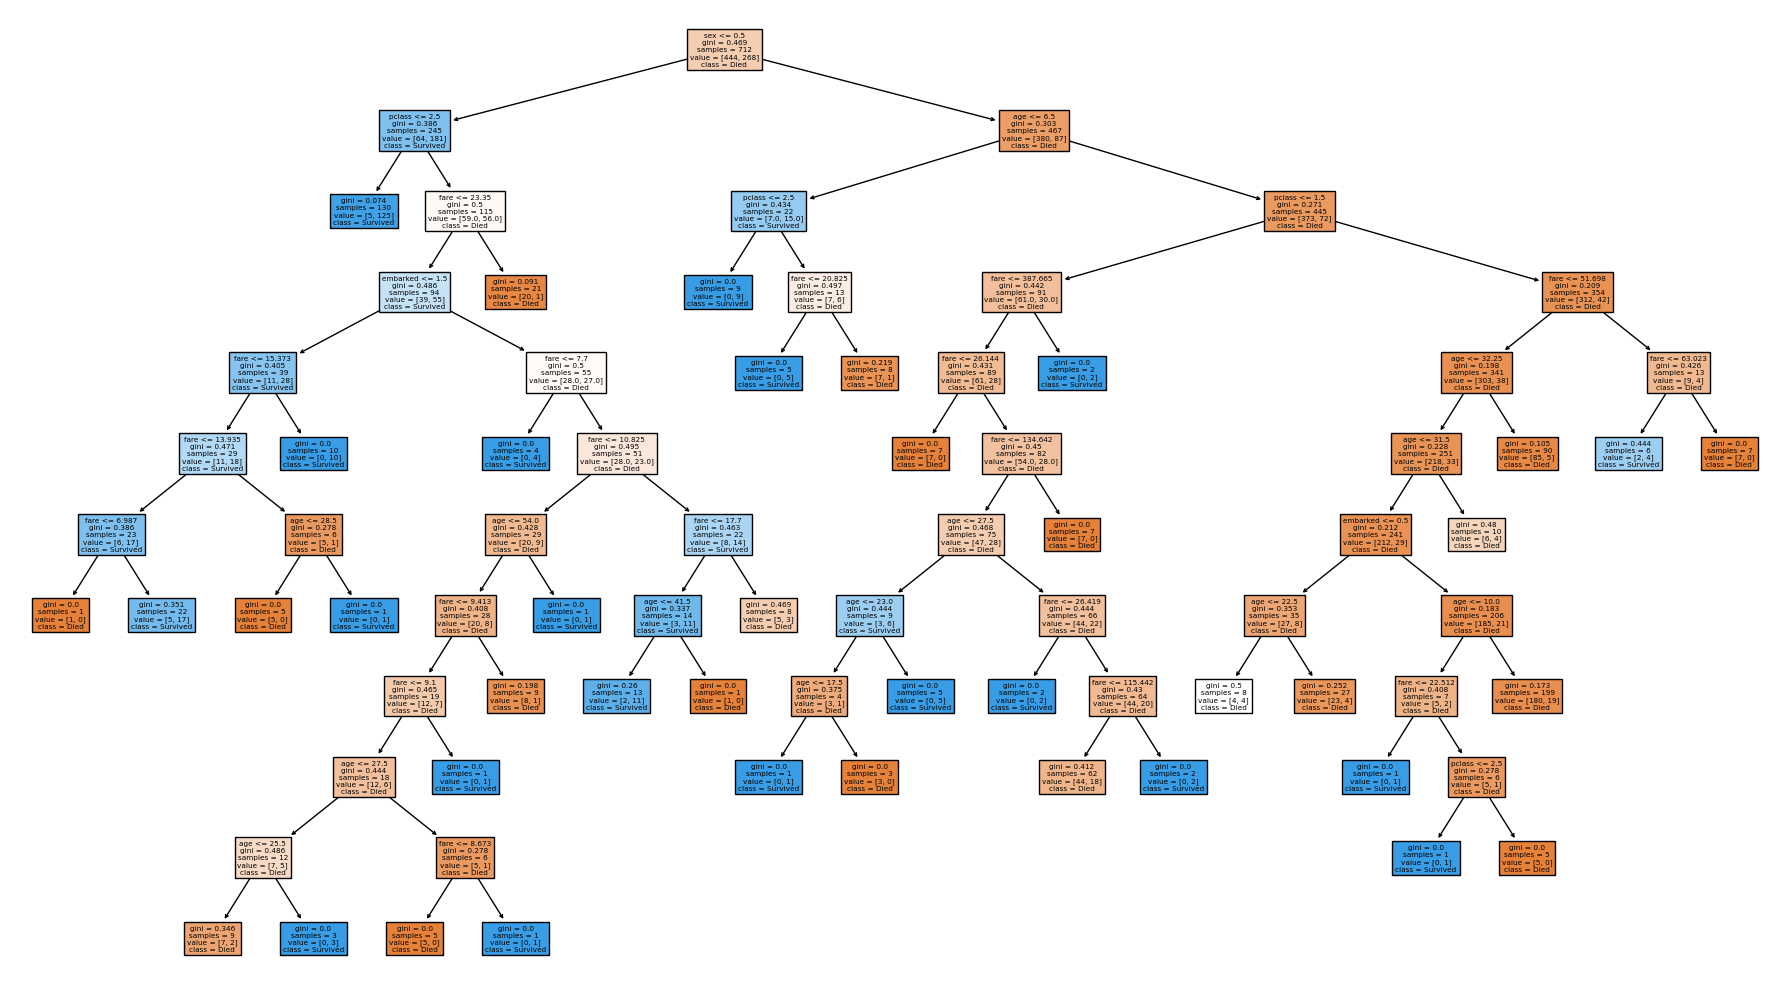

In [25]:
plt.figure(figsize=(18,10))

plot_tree(
    best_model,
    feature_names=X.columns, 
    class_names=["Died","Survived"], 
    filled=True
)
plt.tight_layout()
plt.show()


# Decision tree regressor 

In [61]:
from sklearn.datasets import load_diabetes
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_squared_error

df= load_diabetes(as_frame=True).frame

In [53]:
X=df.drop("target", axis=1)
y= df["target"]

In [55]:
X_train, X_test,y_train, y_test= train_test_split(X,y, random_state=42, test_size=0.3)

In [72]:
model= DecisionTreeRegressor(max_depth=7, min_samples_split=15)
model.fit(X_train,y_train)

DecisionTreeRegressor(max_depth=7, min_samples_split=15)

In [74]:
# checking for overfitting
y_pred_train= model.predict(X_train)
y_pred_test= model.predict(X_test)

print ("MSE: Train", mean_squared_error(y_train, y_pred_train))
print ("MSE: Test", mean_squared_error(y_test, y_pred_test))

print ("R2: Train", r2_score(y_train, y_pred_train))
print ("R2: Test", r2_score(y_test, y_pred_test))

# the results were showing extreame overfitting mse_train=0, r2_train=1, to change them we have done pre-pruning so know its stable

MSE: Train 1694.319918460647
MSE: Test 4084.6807983394406
R2: Train 0.7244238368366305
R2: Test 0.2433405099318675


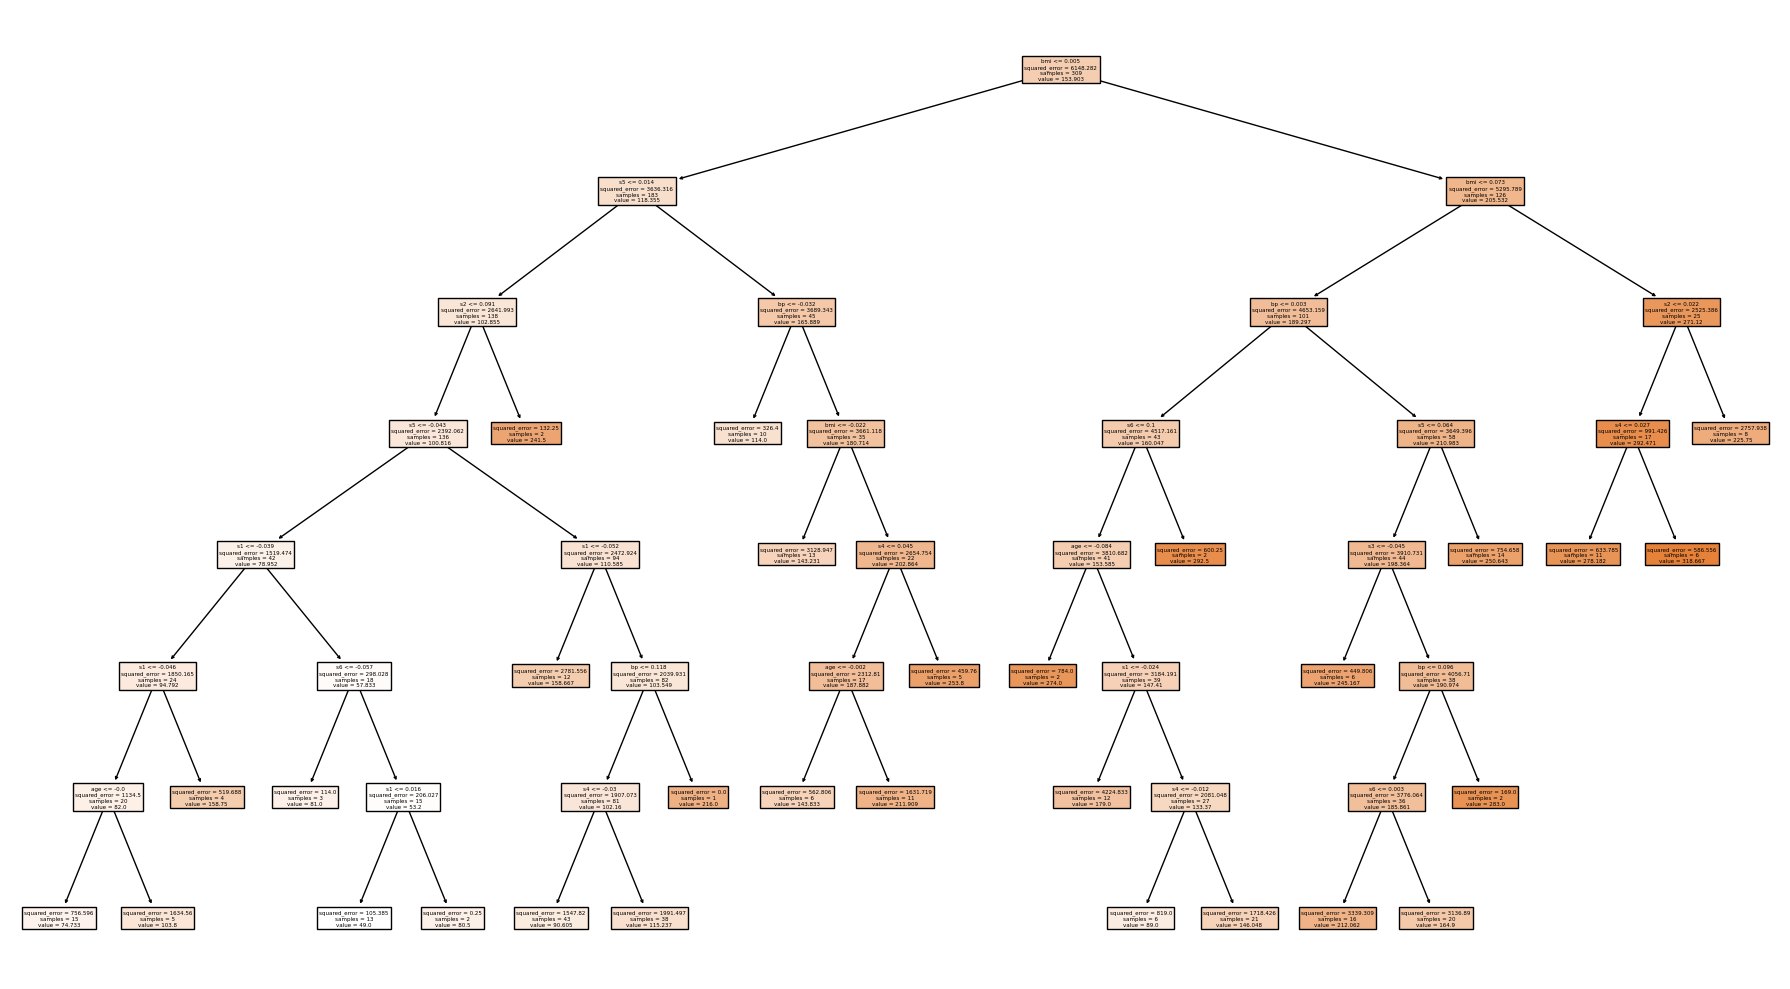

In [78]:
plt.figure(figsize=(18,10))

plot_tree(
    model,
    feature_names=X.columns,
    filled=True
)

plt.tight_layout()
plt.show()